# Delta hedging - final project

## Theory

### Options notation

$S(t)$ - The underlying asset (e.g. Share) price in time t, $S(0)=S$  
$X$ - the eXercise price  
$T$ - expiration date  
$c(t)$ - European 'call' option value at time $t$, $c(0)=c$ is the premium paid in $t=0$  
$p(t)$ - European 'put' option value  
$C(t)$ - American 'Call' option value  
$P(t)$ - American 'Put' option value  

The value of the option at expiration $T$ is:
* $c(T) = C(T) = \max(S(T)-X; 0)$
* $p(T) = P(T) = \max(X-S(T); 0)$

### Stochastic processes

**Itô integral:**
$$ (I)=\int_0^T W(t)\text{d}W(t) = \frac12 W(T)^2 - \frac12 T $$

**Stochastic Differential Equation (SDE):**
$$ \text{d}S = a(S(t),t)\text{d}t + b(S(t),t)\text{dW} \iff S(T) = \int_0^T \overbrace{\underbrace{(a(S(t),t)\text{d}t}_{\text{d}t\text{ integral with random }S(t)} + \underbrace{b(S(t),t)\text{d}W)}_{\text{Itô integral}}}^{\text{d}S} $$

**Geometric Brownian motion:**
$$ \text{d}S = \mu\text{d}t+\sigma\text{d}W \implies S(t) \sim \mathcal{N}(S(0)+\mu t,\ \sigma^2 t)$$
* deterministic part: the trend evolution of the mean value $\langle S(t) \rangle = S(0)+\mu t$
* stochastic part: Gaussian fluctuations around the trend with amplitude $\sim$ standard deviation $=\sigma\sqrt{t}$

More realistic model **(SSB model):**  
$$ \frac{\text{d}S}{S(t)} = \mu\text{d}t+\sigma\text{d}W $$
* $\text{d}S/S(t)$ is the infinitesimal rate of return from the shares, which is modelled to be Gaussian
* rate of return can be negative
* share price evolution:
$$ S(t) = S(0)\exp{\left[\left(\mu-\frac12 \sigma^2\right)t+\sigma W(t)\right]} $$
$\{S(t)\}_t$ is called the **geometric Brownian motion**
Its distribution is **Log-normal:**  
$$ S(t) \sim \int_0^\infty \text{dS} \frac{1}{S\sqrt{2\pi\sigma^2t}}\exp{\left(-\frac{[\ln(S/S(0))-(\mu-\frac12\sigma^2)t]^2}{2\sigma^2t}\right)} $$

### Black-Scholes PDE  
The underlying asset $S(t)$ is described by Geometric Brownian Motion. The option price $V=V(S(t), t)$.  
Portfolio $\Pi$ consists of the long option and the short position in $\Delta$ shares.
$$ \text{d}\Pi = \left( \frac{\partial V}{\partial t}+\frac12\frac{\partial^2 V}{\partial S^2}S^2\sigma^2 \right)\text{d}t + \left( \frac{\partial V}{\partial S}-\Delta \right)\text{d}S $$
Setting $\Delta=\frac{\partial V}{\partial S}$ makes $\Pi$ purely deterministic (risk-free asset).  
If there are no arbitrage opportunities, then the rate of return from $\Pi$ is $r$
$$ \text{d}\Pi = \left( \frac{\partial V}{\partial t}+\frac12\frac{\partial^2 V}{\partial S^2}S^2\sigma^2 \right)\text{d}t = \Pi r\text{d}t = \left(V-\frac{\partial V}{\partial S}S\right)r\text{d}t $$
$$ \implies \frac{\partial V}{\partial S}Sr + \frac12\frac{\partial^2 V}{\partial S^2}S^2\sigma^2 + \frac{\partial V}{\partial t} - rV = 0 \qquad \small{\text{Black-Scholes PDE}}$$
Properties:
* non-stochastic parabolic DE
* very general
* infinitely many solutions

## Model Introduction

### Outline  

1. GBM generation of $S(t)$ in Code and intro in Model Introduction. $\mu, \sigma$ initial parameters.
2. Multi-Brownian generation $S(t, m), \  m=1,2,\dots$ with Monte Carlo (lecture 6)
3. Solving Black-Scholes PDE for $V(t)$
4. Make portfolio out of $S, PV(X), c, p$ to hedge
5. Analyze the outcomes based on hedged vs unhedged, hedging frequency, parameter sensitivity & error accumulation

## Code

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, lognorm
from numba import jit

import catppuccin
plt.style.use(catppuccin.PALETTE.latte.identifier)

### $S(t)$ generation with Geometric Brownian Motion

We can simulate the geometric brownian motion in two ways: generating paths from the gaussian distribution, then taking their logarithm OR generating directly from the LogNorm distribution.

In [2]:
def geometric_brownian(S0, mu, sigma, dt, n, seed=None):
    rng = np.random.default_rng(seed)
    S0 = np.asarray(S0)
    r = norm.rvs(scale=sigma*np.sqrt(dt), size=S0.shape+(n,), random_state=rng)
    log_paths = np.cumsum((mu-0.5*sigma**2)*dt + r, axis=-1)
    return S0[..., None] * np.exp(log_paths)

def geometric_brownian_lognorm(S0, mu, sigma, dt, n, seed=None):
    rng = np.random.default_rng(seed)
    S0 = np.asarray(S0)
    meanlog = (mu - 0.5 * sigma**2) * dt
    sdlog = sigma * np.sqrt(dt)
    R = lognorm.rvs(s=sdlog, scale=np.exp(meanlog), size=S0.shape + (n,), random_state=rng)

    return S0[..., None] * np.cumprod(R, axis=-1)

We can also define functions to produce multiple paths in a vectorized way (`m` - number of paths to simulate).

In [3]:
def multi_brownian(S0, mu, sigma, N, T, m=10, Plots=True, seed=None):
    dt = T/N
    x = np.zeros((m, N+1))
    x[:, 0] = S0
    x[:, 1:] = geometric_brownian(x[:, 0], mu, sigma, dt, N, seed)
    if Plots:
        t = np.linspace(0, T, N+1)
        for k in range(m):
            plt.plot(t, x[k])
        plt.xlabel('$t$')
        plt.ylabel('$S(t)$')
        plt.grid(True)
        plt.show()
    return x


def multi_brownian_lognorm(S0, mu, sigma, N, T, m=10, Plots=True, seed=None):
    dt = T/N
    x = np.zeros((m, N+1))
    x[:, 0] = S0
    x[:, 1:] = geometric_brownian_lognorm(x[:, 0], mu, sigma, dt, N, seed)
    if Plots:
        t = np.linspace(0, T, N+1)
        for k in range(m):
            plt.plot(t, x[k])
        plt.xlabel('$t$')
        plt.ylabel('$S(t)$')
        plt.grid(True)
        plt.show()
    return x

Below we can see that both methods produce the same result.

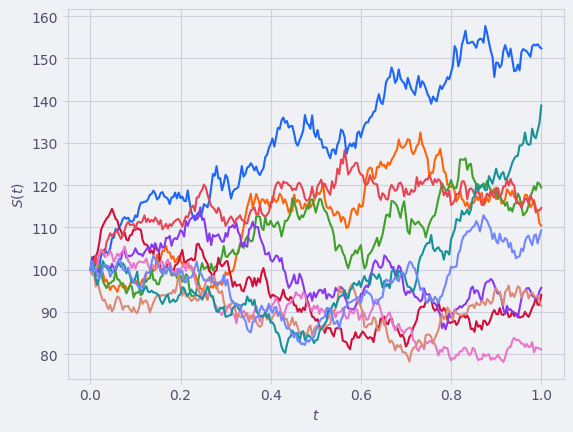

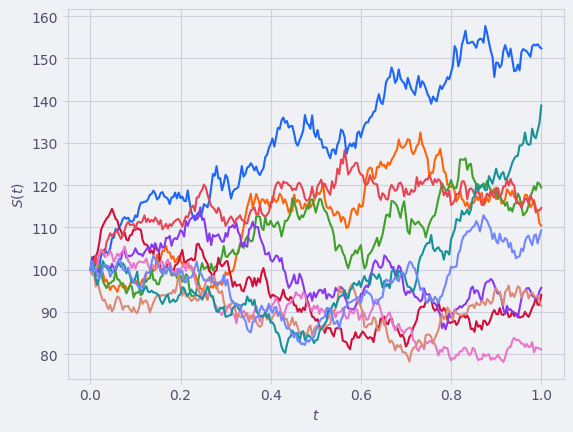

In [4]:
seed = np.abs(hash('GOOGL'))
S = multi_brownian(100, 0.2, 0.2, 250, 1, 10, Plots=True, seed=seed)
S_l = multi_brownian_lognorm(100, 0.2, 0.2, 250, 1, 10, Plots=True, seed=seed)

### Solving Black-Scholes PDE  
The problem can be simplified to a standard diffusion equation with a change of variables:
$$ \tau = T-t $$
$$ x = \ln{S} $$
$$ V = e^{ax + b\tau}u(x,\tau) $$


$$ \implies u_\tau = \frac12\sigma^2u_{xx} \quad \small\text{diffusion equation}$$

$$ F = \frac12\sigma^2u_{xx} $$
We will use the Crank-Nicholson method to solve the diffusion equation numerically.  
For time derivative discretization we use Adams-Moulton trapezoidal rule:
$$ u(x_n, t_k) \equiv u^k_n, \quad x_{n+1} - x_n = h, \quad t_{n+1}-t_n = \lambda h$$
$$ u_n^{k+1} = u_n^k + \frac{\lambda h}{2}(F_n^k + F_n^{k+1}) $$

Let us discretize $u_{xx}$ with
$$ u_{xx}(x_k, t_k) \approx \frac{u^k_{n-1} - 2u^k_n + u^k_{n+1}}{h^2} $$
$$\implies F^k_n = \frac12\sigma^2\frac{u^k_{n-1} - 2u^k_n + u^k_{n+1}}{h^2}. $$

Plugging it in to the Adams-Moulton rule we get:
$$ M_{nm}u_m^{k+1} = b_n, $$
where
$$M_{nm} = \left(1+\frac{\lambda\sigma^2}{2h}\right)\delta{nm} - \frac{\lambda\sigma^2}{4h}(\delta_{n,m-1} + \delta_{n,m+1})$$
is a tridiagonal matrix, and 
$$b_n = \left(1-\frac{\lambda\sigma^2}{2h}\right)u_n^k + \frac{\lambda\sigma^2}{4h}(u_{n-1}^k + u_{n+1}^k).$$

We will use the lazy compilation from Numba's JIT to speed up the execution of the functions wherever possible after they had been called at least once.

Let us create a helper function to perform the Thomas' LU decompostion:

In [5]:
@jit
def Thomas(M, b, u):
    N = len(b)
    matrix = M.copy()
    rhs = b.copy()
    
    for i in range(1, N):
        l = matrix[0][i]/matrix[1][i-1]
        matrix[1][i] = matrix[1][i] - l*matrix[2][i-1]
        rhs[i] = rhs[i] - l*rhs[i-1]

    u[-1] = rhs[-1] / matrix[1][-1]
    for i in range(N-2, -1, -1):
        u[i] = (rhs[i] - matrix[2][i]*u[i+1])/matrix[1][i]
    return u

Then we define the actual solver:

In [6]:
@jit
def solve_BS(x, sigma, X, r, l_h, T, opt_type='c'):
    """
    Solve the Black-Scholes equation.

    Parameters
    ----------
        x : ndarray of float
            Logarithm of share price axis.
        sigma : float
            Volatility.
        X : float
            Exercise price.
        r : float
            Risk-free rate of return.
        l_h : float
            Trapezoidal rule step size.
        T : float
            Time to maturity.
        opt_type : {'c', 'p'}, default: 'c'
            Option type.

    Returns
    -------
        t : ndarray of float
            Time axis.
        res : ndarray of float
            Option value vs share price data for each time step of t, in the problem-simplifying variables.
    """
    dx = x[1]-x[0]
    sigma2 = sigma**2
    dt = l_h*dx**2/sigma2
    nsteps = int(T / dt) + 1
    
    A = 0.5 - r/sigma2
    B = 0.5*sigma2*A*A + (r - 0.5*sigma2)*A - r
    S = np.exp(x)
    
    if opt_type == 'c':
        u = np.exp(-A*x) * np.maximum(S - X, 0)
    elif opt_type == 'p':
        u = np.exp(-A*x) * np.maximum(X - S, 0)
    
    q = 0.25 * l_h
    v = q * np.ones_like(u)
    
    N = len(x)
    M = np.zeros((3, N))
    M[0, :] = -v
    M[1, :] = 1 + 2*v
    M[2, :] = -v
    
    M[1,0] = 1; M[0,0] = 0; M[2,0] = 0
    M[1,-1] = 1; M[0,-1] = 0; M[2,-1] = 0
    
    res = np.zeros((N, nsteps + 1))
    t = np.zeros(nsteps + 1)

    res[:, 0] = u
    t[0] = 0.0
    
    for n in range(nsteps):
        tau = min((n+1)*dt, T)
        b = np.empty_like(u)
        b[1:-1] = (1-2*q)*u[1:-1] + q*(u[2:] + u[0:-2])
        if opt_type == 'c':
            b[0] = 0.0
            b[-1] = np.exp(-A*x[-1] - B*tau)*(np.exp(x[-1]) - X*np.exp(-r*tau))
        elif opt_type == 'p':
            b[0] = np.exp(-A*x[0] - B*tau) * X * np.exp(-r*tau)
            b[-1] = 0.0
            
        u = Thomas(M, b, u)
        res[:, n+1] = u
        t[n+1] = tau
    return t, res

@jit
def u_to_V(x, u, sigma, r, t):
    """
    Change variables back to original.

    Parameters
    ----------
        x : ndarray of float
            Logarithm of share price axis.
        u : ndarray of float
            Option values in problem-simplifying variables.
        sigma: float
            Volatility.
        r : float
            Risk-free rate of return.
        t : ndarray of float
            Time axis.
    
    Returns
    -------
        S : ndarray of float
            Share price axis.
        V : ndarray of float
            Option value data.
    """
    sigma2 = sigma**2
    A = 0.5 - r/sigma2
    B = 0.5*sigma2*A*A + (r - 0.5*sigma2)*A - r
    S = np.exp(x)
    V = np.exp(A*x[:,None] + B*t[None,:]) * u
    return S, V

Let us define the required parameters:

In [7]:
X = 100
sigma = 0.2
S_max = 5*X
S_min = 0*X
N = 5000
r = 0.05
T = 1
l_h = 0.1
x = np.linspace(np.log(S_min+1e-06), np.log(S_max), N)

We will first run the solver on a coarser grid to let it compile.

In [8]:
%%time
x_compile = np.linspace(np.log(S_min+1e-06), np.log(S_max), N//100)
t_compile, res_compile = solve_BS(x_compile, sigma, X, r, 0.9, T, opt_type='c')

CPU times: user 3.09 s, sys: 36.8 ms, total: 3.12 s
Wall time: 3.16 s


Then we run the proper computation for a call option. It achieves similar execution time to the previous coarser example.

In [9]:
%%time
tc, res_c = solve_BS(x, sigma, X, r, l_h, T, opt_type='c')

CPU times: user 3.25 s, sys: 300 ms, total: 3.55 s
Wall time: 3.56 s


Back to original variables:

In [10]:
Sc, Vc = u_to_V(x, res_c, sigma, r, tc)

The same process for a put option.

In [11]:
%%time
tp, res_p = solve_BS(x, sigma, X, r, l_h, T, opt_type='p')

CPU times: user 3 s, sys: 302 ms, total: 3.3 s
Wall time: 3.31 s


In [12]:
Sp, Vp = u_to_V(x, res_p, sigma, r , tp)

Below we define the analytical solutions to our problem.

In [13]:
def analytic_call(S, X, T, r, sigma):
    d1 = (np.log(S/X) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return S*norm.cdf(d1) - X*np.exp(-r*T)*norm.cdf(d2)

def analytic_put(S, X, T, r, sigma):
    d1 = (np.log(S/X) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = -d1 + sigma*np.sqrt(T)
    return  X*np.exp(-r*T)*norm.cdf(d2) - S*norm.cdf(-d1)

We present the resulting time evolution of the option value vs share price for both option types, compared with the analytical solution at $t=0$.

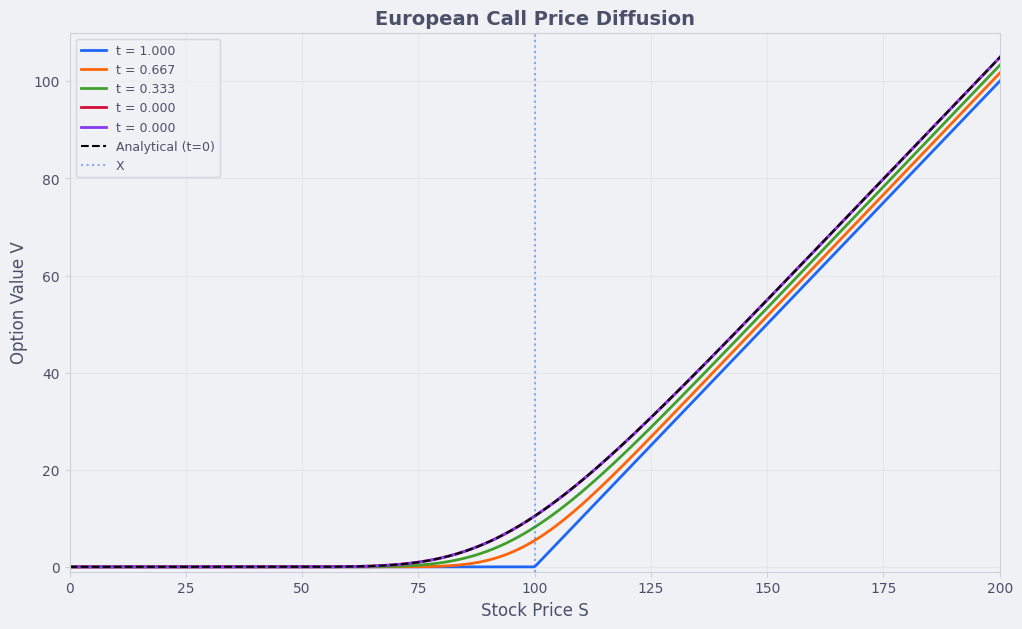

In [ ]:
plt.figure(figsize=(12, 7))

skip = len(tc) // 3
indices = range(0, len(tc), skip)

for idx in indices:
    real_time = T - tc[idx]
    plt.plot(Sc, Vc[:, idx], linewidth=2, label=f't = {real_time:.3f}')
real_time = T - tc[-1]
plt.plot(Sc, Vc[:, -1], linewidth=2, label=f't = {real_time:.3f}')

Vc_analytic = analytic_call(Sc, X, T, r, sigma)
plt.plot(Sc, Vc_analytic, 'k--', linewidth=1.5, label='Analytical (t=0)', alpha=1)

plt.axvline(X, linestyle=':', alpha=0.5, linewidth=1.5, label='X')

plt.xlabel('Stock Price S', fontsize=12)
plt.ylabel('Option Value V', fontsize=12)
plt.title('European Call Price Diffusion', fontsize=14, fontweight='bold')
plt.legend(loc='upper left', fontsize=9)
plt.grid(True, alpha=0.3)
plt.xlim([0, 2*X])
plt.ylim([-1, 110])
plt.show()

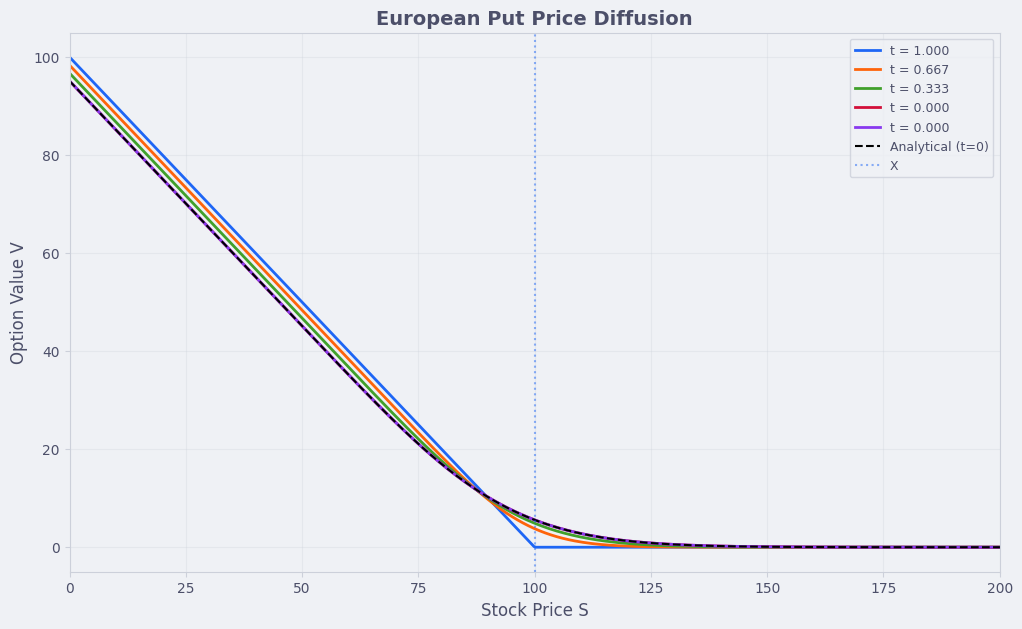

In [ ]:
plt.figure(figsize=(12, 7))

skip = len(tp) // 3
indices = range(0, len(tp), skip)

for idx in indices:
    real_time = T - tp[idx]
    plt.plot(Sp, Vp[:, idx], linewidth=2, label=f't = {real_time:.3f}')
real_time = T - tp[-1]
plt.plot(Sp, Vp[:, -1], linewidth=2, label=f't = {real_time:.3f}')

Vp_analytic = analytic_put(Sp, X, T, r, sigma)
plt.plot(Sp, Vp_analytic, 'k--', linewidth=1.5, label='Analytical (t=0)', alpha=1)

plt.axvline(X, linestyle=':', alpha=0.5, linewidth=1.5, label='X')

plt.xlabel('Stock Price S', fontsize=12)
plt.ylabel('Option Value V', fontsize=12)
plt.title('European Put Price Diffusion', fontsize=14, fontweight='bold')
plt.legend(loc='upper right', fontsize=9)
plt.grid(True, alpha=0.3)
plt.xlim([0, 2*X])
plt.show()

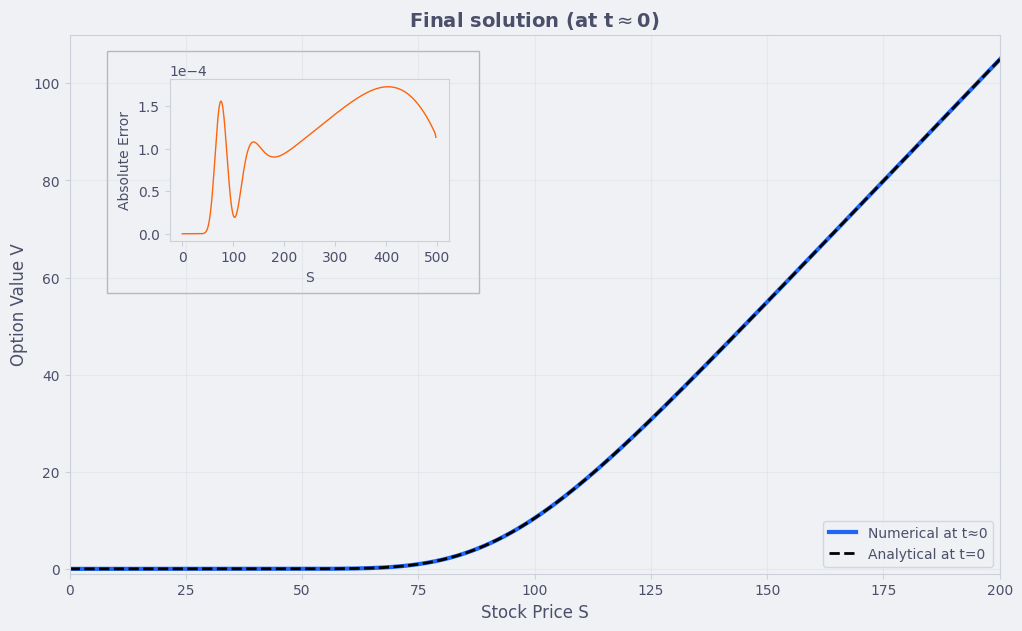

Mean absolute error: 0.000012
Max absolute error: 0.000173
Max relative error: 0.026316


In [ ]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Rectangle

fig = plt.figure(figsize=(12, 7))
ax = fig.add_subplot()

ax.plot(Sc, Vc[:, -1], '-', linewidth=3, label='Numerical at t≈0')
ax.plot(Sc, Vc_analytic, 'k--', linewidth=2, label='Analytical at t=0')
ax.set_xlabel('Stock Price S', fontsize=12)
ax.set_ylabel('Option Value V', fontsize=12)
ax.set_title(r'Final solution (at t$\approx$0)', fontsize=14, fontweight='bold')
ax.legend(loc="lower right")
plt.grid(True, alpha=0.3)
ax.set_xlim([0, 200])
ax.set_ylim([-1, 110])

error = np.abs(Vc[:-1, -1] - Vc_analytic[:-1])
axins = inset_axes(ax, width='30%', height='30%', loc="upper left", bbox_to_anchor=(0.1,-.07,1,1), bbox_transform=ax.transAxes)
axins.plot(Sc[:-1], error, 'C1', linewidth=1)
axins.set_xlabel('S', fontsize=10)
axins.set_ylabel('Absolute Error', fontsize=10)
axins.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

rect = Rectangle(
    (0.04, 0.52),
    0.4,
    0.45,
    transform=ax.transAxes,
    fill=False,
    edgecolor='gray',
    alpha=0.5,
    linewidth=1
)
ax.add_patch(rect)
plt.show()
print(f"Mean absolute error: {np.mean(error):.6f}")
print(f"Max absolute error: {np.max(error):.6f}")
print(f"Max relative error: {np.max(error / (Vc_analytic[:-1] + 1e-10)):.6f}")

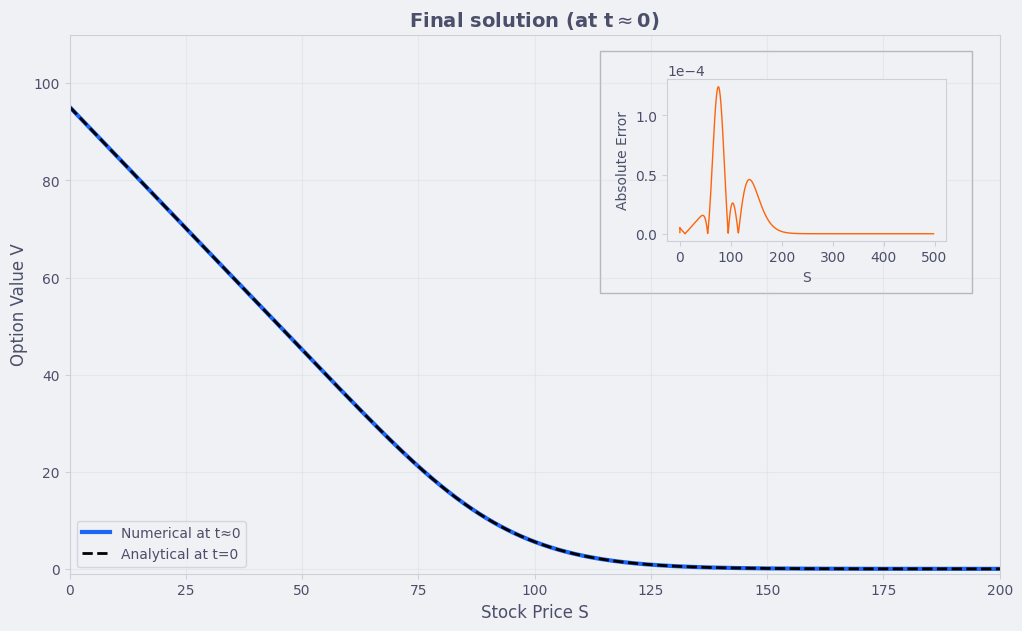

Mean absolute error: 0.000007
Max absolute error: 0.000124
Max relative error: 0.021399


In [ ]:
fig = plt.figure(figsize=(12, 7))
ax = fig.add_subplot()

ax.plot(Sp, Vp[:, -1], '-', linewidth=3, label='Numerical at t≈0')
ax.plot(Sp, Vp_analytic, 'k--', linewidth=2, label='Analytical at t=0')
ax.set_xlabel('Stock Price S', fontsize=12)
ax.set_ylabel('Option Value V', fontsize=12)
ax.set_title(r'Final solution (at t$\approx$0)', fontsize=14, fontweight='bold')
ax.legend(loc="lower left")
plt.grid(True, alpha=0.3)
ax.set_xlim([0, 200])
ax.set_ylim([-1, 110])

error = np.abs(Vp[:-1, -1] - Vp_analytic[:-1])
axins = inset_axes(ax, width='30%', height='30%', loc="upper right", bbox_to_anchor=(-0.05,-.07,1,1), bbox_transform=ax.transAxes)
axins.plot(Sp[:-1], error, 'C1', linewidth=1)
axins.set_xlabel('S', fontsize=10)
axins.set_ylabel('Absolute Error', fontsize=10)
axins.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

rect = Rectangle(
    (0.57, 0.52),
    0.4,
    0.45,
    transform=ax.transAxes,
    fill=False,
    edgecolor='gray',
    alpha=0.5,
    linewidth=1
)
ax.add_patch(rect)
plt.show()
print(f"Mean absolute error: {np.mean(error):.6f}")
print(f"Max absolute error: {np.max(error):.6f}")
print(f"Max relative error: {np.max(error / (Vp_analytic[:-1] + 1e-10)):.6f}")

Finally we check whether the $\Delta$ and $\Gamma$ derivatives assume the correct form for both option types.

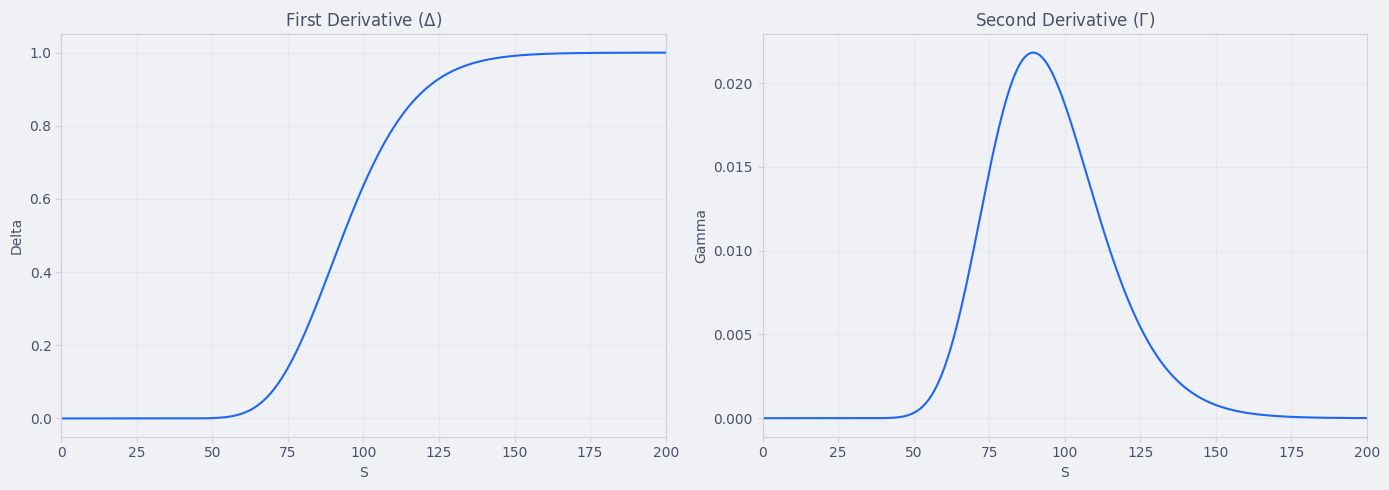

In [ ]:
delta = np.gradient(Vc[:, -1], Sc)
gamma = np.gradient(delta, Sc)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(Sc, delta)
axes[0].set_xlabel('S')
axes[0].set_ylabel('Delta')
axes[0].set_title(r'First Derivative ($\Delta$)')
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim([0, 200])

axes[1].plot(Sc, gamma)
axes[1].set_xlabel('S')
axes[1].set_ylabel('Gamma')
axes[1].set_title(r'Second Derivative ($\Gamma$)')
axes[1].grid(True, alpha=0.3)
axes[1].set_xlim([0, 200])

plt.tight_layout()
plt.show()

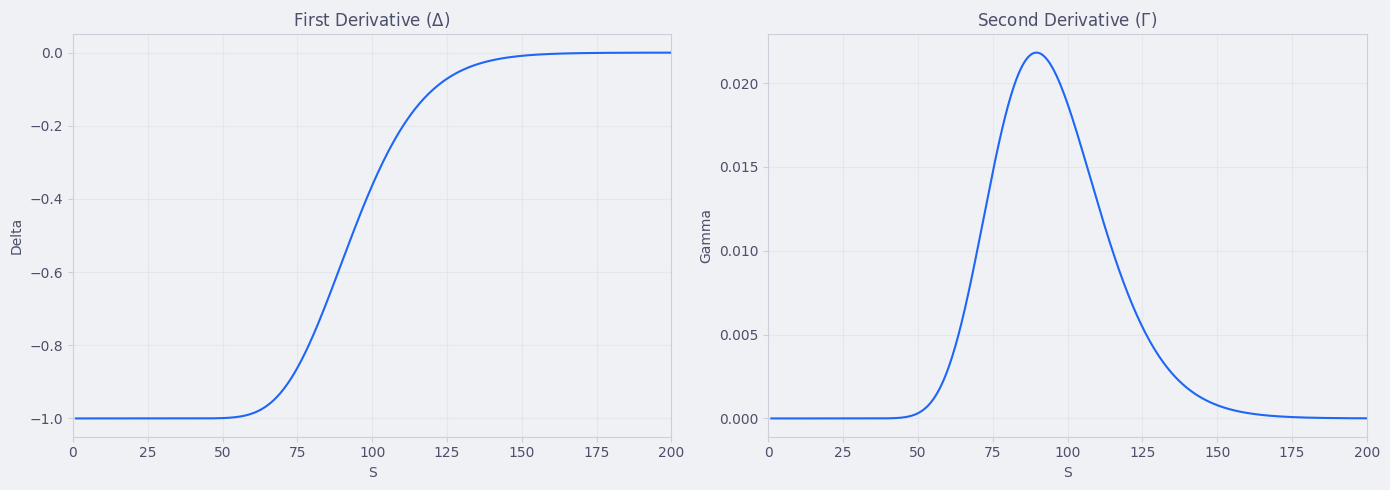

In [ ]:
mask = Sp>1
delta1 = np.gradient(Vp[:, -1][mask], Sp[mask])
gamma1 = np.gradient(delta1, Sp[mask])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(Sp[mask], delta1)
axes[0].set_xlabel('S')
axes[0].set_ylabel('Delta')
axes[0].set_title(r'First Derivative ($\Delta$)')
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim([0, 200])

axes[1].plot(Sp[mask], gamma1)
axes[1].set_xlabel('S')
axes[1].set_ylabel('Gamma')
axes[1].set_title(r'Second Derivative ($\Gamma$)')
axes[1].grid(True, alpha=0.3)
axes[1].set_xlim([0, 200])

plt.tight_layout()
plt.show()

## Delta Hedging Strategy Analysis

We will analyse the strategy for the European call option type.

### Hedged vs Unhedged Portfolio

Let us define the function for computing $\Delta$ and set the required parameters:

In [20]:
def bs_call_delta(S, X, T, r, sigma):
    if T <= 0:
        return 1.0 if S > X else 0.0
    d1 = (np.log(S/X) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    return norm.cdf(d1)

In [21]:
S0 = 100
X = 110
T = 1.0
r = 0.05
sigma = 0.2
c0 = analytic_call(S0, X, T, r, sigma)
n_steps = 252
n_paths = 100000
seed = np.abs(hash('GOOGL'))

Then we simulate the share price paths and set the hedging time grid.

In [22]:
stock_paths = multi_brownian(S0, r, sigma, n_steps, T, m=n_paths, Plots=False, seed=seed)
time_grid   = np.linspace(0, T, n_steps + 1)

We perform the delta hedging strategy on one portfolio and compare it with an unhedged one.

In [23]:
%%time
B_h = c0 * np.ones(n_paths)
B_u = c0 * np.ones(n_paths)
delta = np.zeros(n_paths)
tau = T - time_grid
dt = T/n_steps
V_hedged = np.zeros((n_paths, n_steps + 1))
V_unhedged = np.zeros((n_paths, n_steps + 1))

for step in range(n_steps + 1):
    if tau[step] > 1e-10:
        delta_new = bs_call_delta(stock_paths[:, step], X, tau[step], r, sigma)
        c_t = analytic_call(stock_paths[:, step], X, tau[step], r, sigma)

        B_h -= (delta_new - delta) * stock_paths[:, step]
        delta = delta_new
    
        V_hedged[:, step] = delta * stock_paths[:, step] + B_h - c_t
        V_unhedged[:, step] = B_u - c_t
    
        if step < n_steps:
            B_h *= np.exp(r*dt)
            B_u *= np.exp(r*dt)

    else:
        payoff = np.maximum(stock_paths[:, step] - X, 0.0)
        V_hedged[:, step]   = delta * stock_paths[:, step] + B_h - payoff
        V_unhedged[:, step] = B_u - payoff

CPU times: user 3.61 s, sys: 24.3 ms, total: 3.64 s
Wall time: 3.67 s


Below we present the comparison.

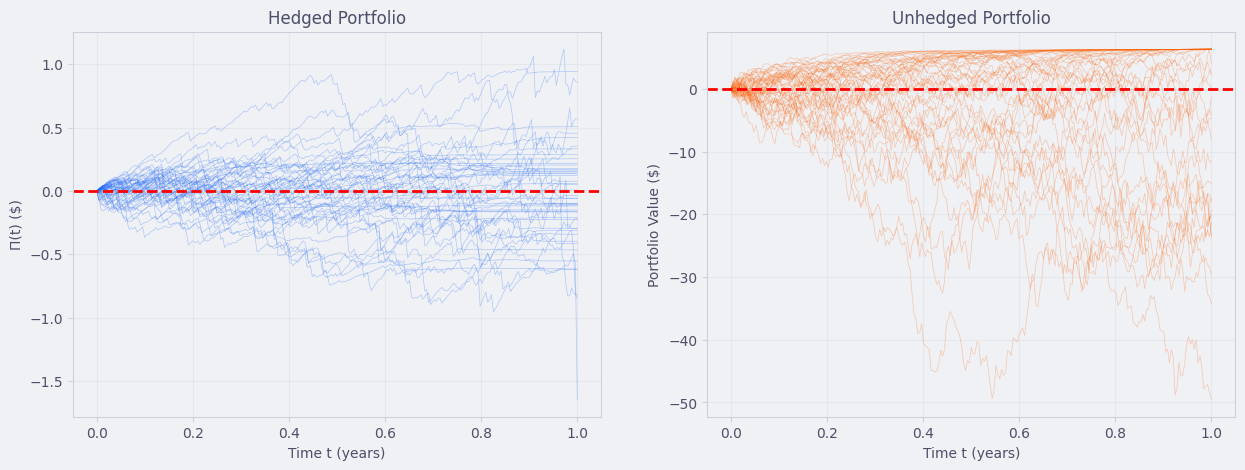

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
for i in range(min(50, n_paths)):
    ax.plot(time_grid, V_hedged[i, :], alpha=0.3, linewidth=0.5, color='C0')
ax.axhline(0, color='red', linestyle='--', linewidth=2)
ax.set_xlabel('Time t (years)')
ax.set_ylabel('Π(t) ($)')
ax.set_title('Hedged Portfolio')
ax.grid(True, alpha=0.3)

ax = axes[1]
for i in range(min(50, n_paths)):
    ax.plot(time_grid, V_unhedged[i, :], alpha=0.3, linewidth=0.5, color='C1')
ax.axhline(0, color='red', linestyle='--', linewidth=2)
ax.set_xlabel('Time t (years)')
ax.set_ylabel('Portfolio Value ($)')
ax.set_title('Unhedged Portfolio')
ax.grid(True, alpha=0.3)
plt.show()

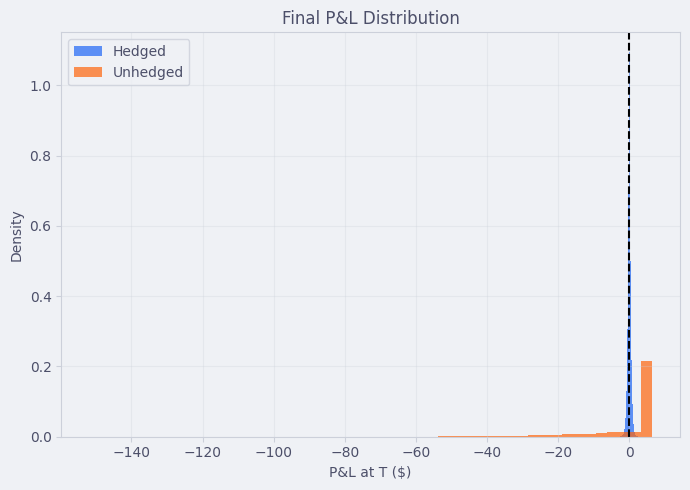

In [ ]:
fig, axes = plt.subplots(1, 1, figsize=(7, 5))
ax = axes
PnL_hedged = V_hedged[:, -1]
PnL_unhedged = V_unhedged[:, -1]
ax.hist(PnL_hedged, bins=50, alpha=0.7, label='Hedged', density=True)
ax.hist(PnL_unhedged, bins=50, alpha=0.7, label='Unhedged', density=True)
ax.axvline(0, color='black', linestyle='--')
ax.set_xlabel('P&L at T ($)')
ax.set_ylabel('Density')
ax.set_title('Final P&L Distribution')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [26]:
df = pd.DataFrame({
    'Hedged': PnL_hedged,
    'Unhedged': PnL_unhedged
})
df.describe().loc[['mean', 'std', 'min', 'max']]

,Hedged,Unhedged
mean,-0.000929,-0.008175
std,0.470201,12.215898
min,-3.797707,-151.802696
max,3.095346,6.349770


By hedging we achieve the following variance reduction:

In [27]:
var_reduction = (1 - df['Hedged'].var() / df['Unhedged'].var()) * 100
print(f"\nVariance Reduction: {var_reduction:.2f}%")


Variance Reduction: 99.85%


### Rebalancing Frequency

Below we compare the hedging results for a set of different portfolio rebalancing frequencies.

In [28]:
frequencies = {
    'Daily': 252,
    'Weekly': 52,
    'Bi-weekly': 26,
    'Monthly': 12
}

In [29]:
%%time
freq_results = {}

for name, N in frequencies.items():
    stock_paths = multi_brownian(S0, r, sigma, N, T, m=n_paths, Plots=False, seed=seed)
    t = np.linspace(0, T, N+1)
    dt = T/N
    PnL = np.zeros(n_paths)
    n_trades = np.zeros(n_paths)    
    
    B = c0 * np.ones(n_paths)
    delta = np.zeros(n_paths)
    trades = np.zeros(n_paths)
    tau = T - t
    
    for step in range(N + 1):
        if tau[step] > 1e-10:
            delta_new = bs_call_delta(stock_paths[:, step], X, tau[step], r, sigma)

            trades_mask =  np.abs(delta_new - delta) > 1e-10
            trades[trades_mask] += 1
    
            B -= (delta_new - delta) * stock_paths[:, step]
            delta = delta_new
        
            if step < N:
                B *= np.exp(r*dt)
    
        else:
            payoff = np.maximum(stock_paths[:, step] - X, 0.0)
            PnL = delta * stock_paths[:, step] + B - payoff
            n_trades = trades

    freq_results[name] = pd.DataFrame({'PnL': PnL, 'trades': n_trades})

CPU times: user 2.4 s, sys: 99.7 ms, total: 2.5 s
Wall time: 2.54 s


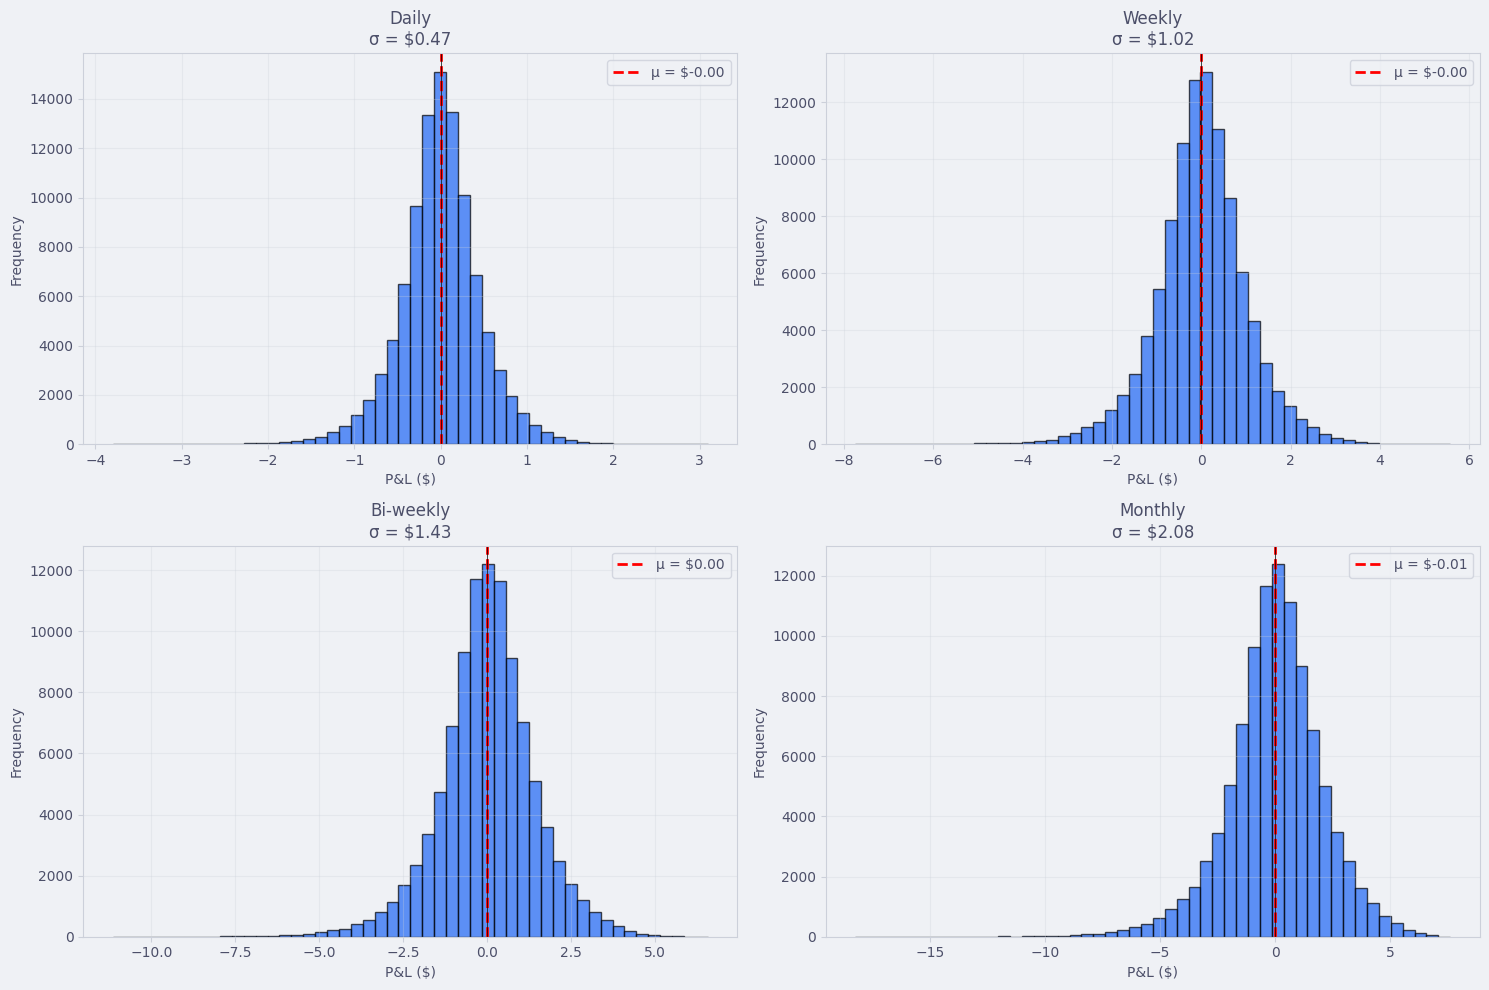

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for idx, (name, data) in enumerate(freq_results.items()):
    ax = axes[idx // 2, idx % 2]
    ax.hist(data['PnL'], bins=50, alpha=0.7, edgecolor='black')
    ax.axvline(data['PnL'].mean(), color='red', linestyle='--',
               linewidth=2, label=f"μ = ${data['PnL'].mean():.2f}")
    ax.axvline(0, color='black', linestyle='-', linewidth=0.5)
    ax.set_xlabel('P&L ($)')
    ax.set_ylabel('Frequency')
    ax.set_title(f'{name}\nσ = ${data["PnL"].std():.2f}')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
freq_results['Daily'].describe().loc[['mean', 'std', 'min', 'max']]

,PnL,trades
mean,-0.000929,246.650890
std,0.470201,8.378563
min,-3.797707,154.000000
max,3.095346,252.000000


In [32]:
freq_results['Weekly'].describe().loc[['mean', 'std', 'min', 'max']]

,PnL,trades
mean,-0.002234,51.443790
std,1.020734,1.353787
min,-7.741550,36.000000
max,5.569853,52.000000


In [33]:
freq_results['Bi-weekly'].describe().loc[['mean', 'std', 'min', 'max']]

,PnL,trades
mean,0.001109,25.875870
std,1.432236,0.481149
min,-11.144387,18.000000
max,6.578780,26.000000


In [34]:
freq_results['Monthly'].describe().loc[['mean', 'std', 'min', 'max']]

,PnL,trades
mean,-0.005155,11.993100
std,2.076806,0.087593
min,-18.224354,9.000000
max,7.604245,12.000000


### Volatility and eXercise Price sensitivity

Let us test the strategy's response to different market conditions.

In [35]:
%%time
sigmas  = 0.1*(np.arange(4) + 1)
eXercises = np.array([90, 100, 110])
n_sim   = 5000
N       = 252
t = np.linspace(0, T, N+1)
tau = T - t
dt = T / N

sensitivity = {}

for sig in sigmas:
    for X in eXercises:
        key = f"sigma={sig:.1f}, X={X}"

        stock_paths = multi_brownian(S0, r, sig, N, T, m=n_sim, Plots=False, seed=seed)

        PnL = np.zeros(n_sim)

        B = analytic_call(S0, X, T, r, sig)
        delta = np.zeros_like(PnL)


        for step in range(N + 1):
            if tau[step] > 1e-10:
                delta_new = bs_call_delta(stock_paths[:, step], X, tau[step], r, sig)
        
                B -= (delta_new - delta) * stock_paths[:, step]
                delta = delta_new
            
                if step < N:
                    B *= np.exp(r*dt)
        
            else:
                payoff = np.maximum(stock_paths[:, step] - X, 0.0)
                PnL = delta * stock_paths[:, step] + B - payoff

        sensitivity[key] = PnL

CPU times: user 893 ms, sys: 28.6 ms, total: 922 ms
Wall time: 929 ms


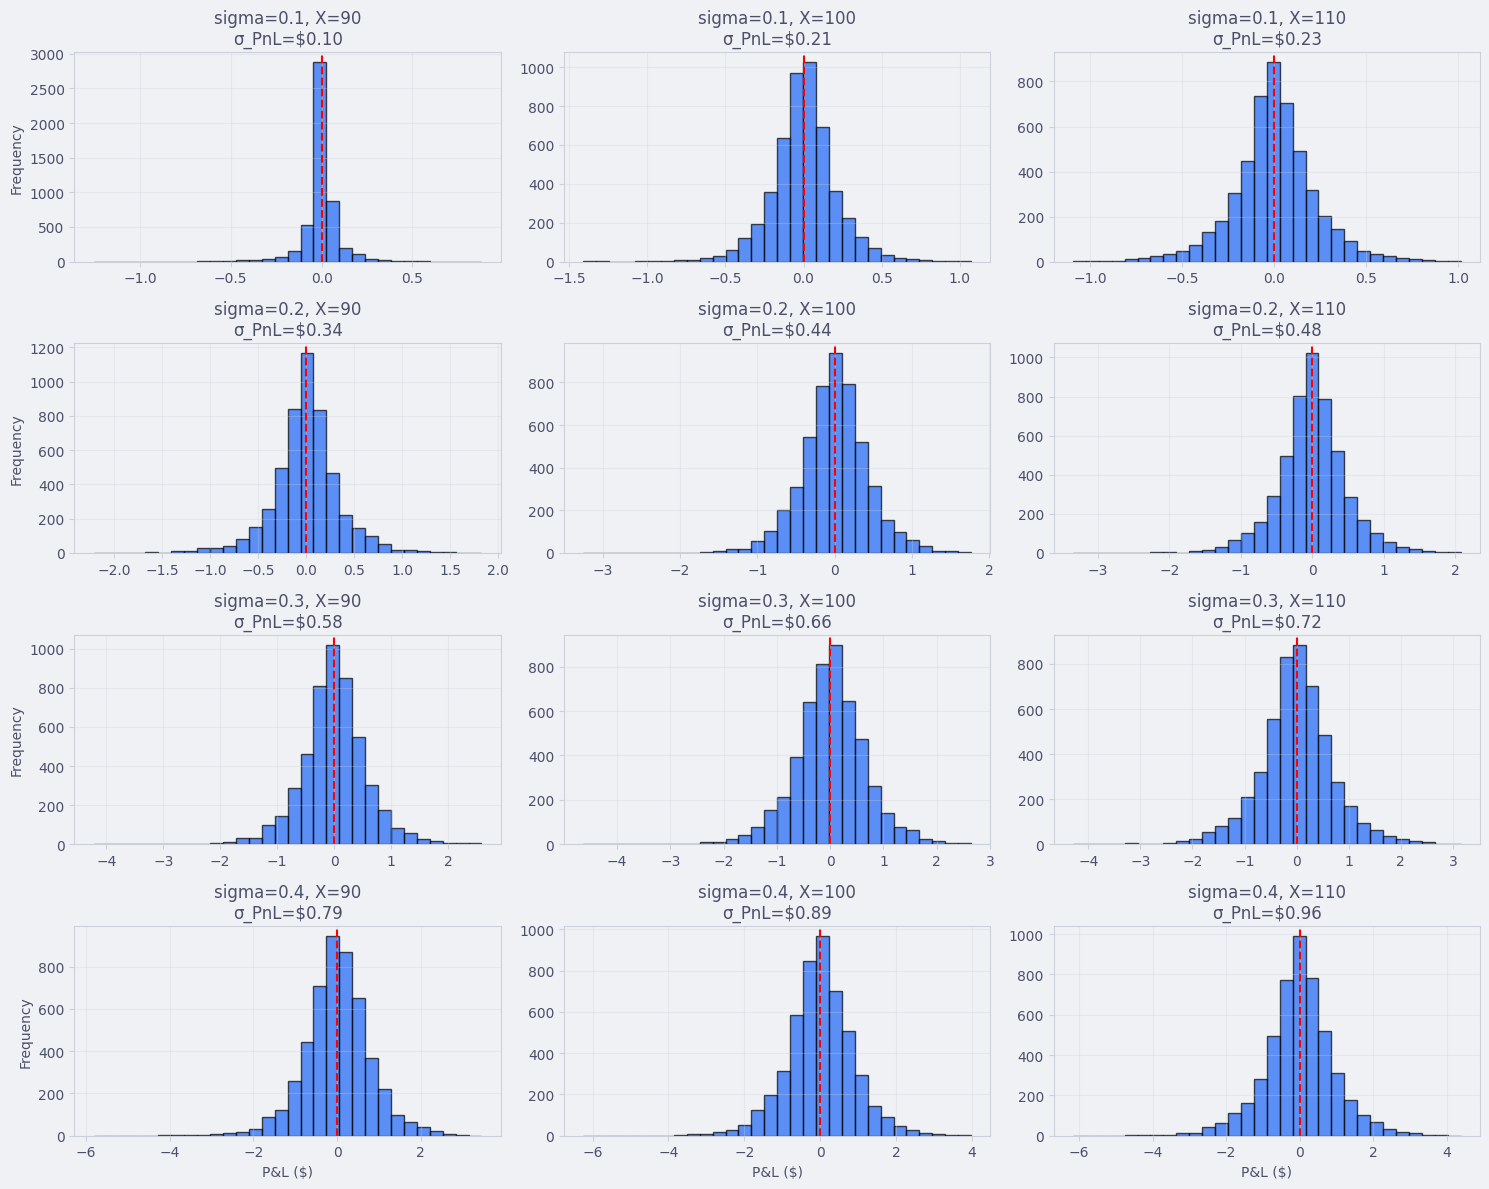

In [ ]:
fig, axes = plt.subplots(len(sigmas), len(eXercises), figsize=(15, 12))

for i, sig in enumerate(sigmas):
    for j, X in enumerate(eXercises):
        key = f"sigma={sig:.1f}, X={X}"
        ax = axes[i, j]

        ax.hist(sensitivity[key], bins=30, alpha=0.7, edgecolor='black')
        ax.axvline(0, color='red', linestyle='--')
        ax.set_title(f'{key}\nσ_PnL=${np.std(sensitivity[key]):.2f}')

        if i == len(sigmas) - 1:
            ax.set_xlabel('P&L ($)')
        if j == 0:
            ax.set_ylabel('Frequency')
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Hedging Error Accumulation

Finally, we compare the error accumulation for different rebalancing frequencies.

In [37]:
%%time
intervals = [252, 52, 12, 4]
errors = {}
n_sim = 100
X = 100


for N in intervals:
    t = np.linspace(0, T, N + 1)
    tau = T - t
    dt = T/N
    
    stock_paths = multi_brownian(S0, r, sigma, N, T, m=n_sim, Plots=False, seed=seed)
    error = np.zeros_like(stock_paths)
    PnL = np.zeros(n_sim)

    B = c0 * np.ones_like(PnL)
    delta = np.zeros_like(PnL)

    for step in range(N + 1):
        if tau[step] > 1e-10:
            delta_new = bs_call_delta(stock_paths[:, step], X, tau[step], r, sigma)
            c_t = analytic_call(stock_paths[:, step], X, tau[step], r, sigma)
    
            B -= (delta_new - delta) * stock_paths[:, step]
            delta = delta_new
        
            if step < N:
                B *= np.exp(r*dt)
            
            error[:, step] = delta * stock_paths[:, step] + B - c_t
            
        else:
            payoff = np.maximum(stock_paths[:, step] - X, 0.0)
            error[:, step] = delta * stock_paths[:, step] + B - payoff
            
    errors[N] = (t, error)

CPU times: user 51.2 ms, sys: 950 μs, total: 52.1 ms
Wall time: 51.2 ms


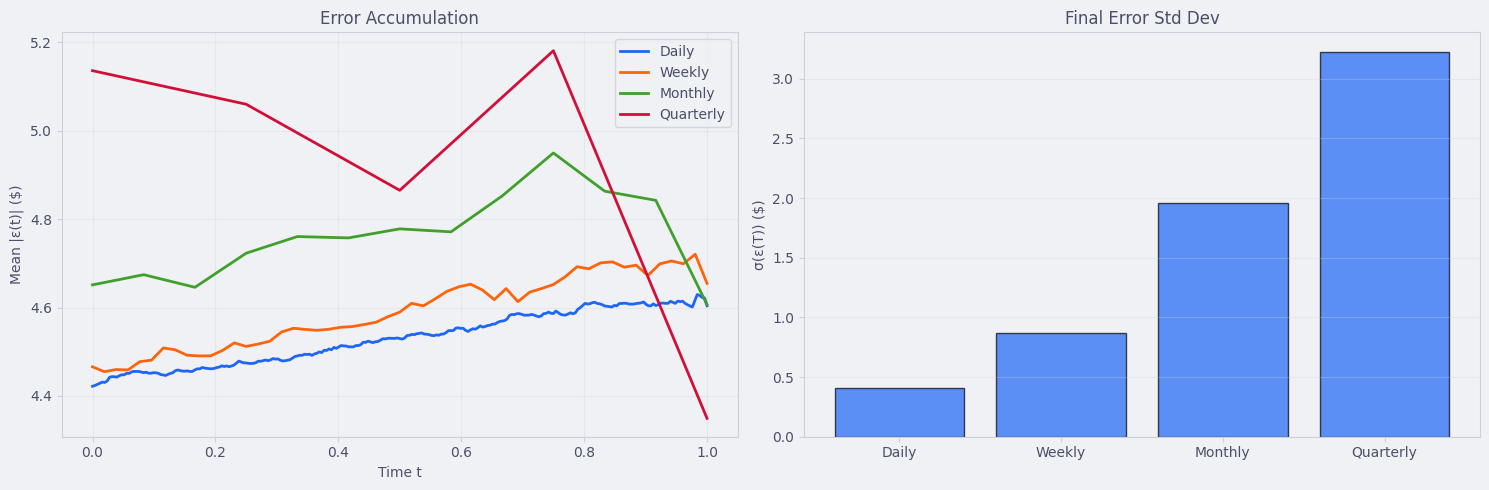

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

labels = {252: 'Daily', 52: 'Weekly', 12: 'Monthly', 4: 'Quarterly'}
for N, (t, error) in errors.items():
    mean_abs = np.mean(np.abs(error), axis=0)
    ax1.plot(t, mean_abs, linewidth=2, label=labels[N])

ax1.set_xlabel('Time t')
ax1.set_ylabel('Mean |ε(t)| ($)')
ax1.set_title('Error Accumulation')
ax1.legend()
ax1.grid(True, alpha=0.3)

final_std = [np.std(errors[N][1][:, -1]) for N in intervals]
ax2.bar([labels[N] for N in intervals], final_std, alpha=0.7, edgecolor='black')
ax2.set_ylabel('σ(ε(T)) ($)')
ax2.set_title('Final Error Std Dev')
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()